# Proyek Analisis Data: Air Quality Dataset (PRSA Beijing)
- **Nama:** Azzahra Anggarista Yoan Putri
- **Email:** zayoraanggarista@gmail.com
- **ID Dicoding:** DS284B6X0316

## Menentukan Pertanyaan Bisnis

**Konteks:** Dataset berisi data per jam kualitas udara dan cuaca dari **12 stasiun pemantau di Beijing** (1 Maret 2013 – 28 Februari 2017). Polutan utama yang menjadi fokus adalah **PM2.5**, karena paling berbahaya bagi kesehatan.

- **Pertanyaan 1:** Pada bulan apa rata-rata PM2.5 di 12 stasiun Beijing mencapai level tertinggi dan terendah selama Maret 2013 – Februari 2017, dan apakah rata-rata PM2.5 per periode tahunan (Maret–Februari) menunjukkan penurunan dibandingkan periode 2013/2014 sebagai acuan?
- **Pertanyaan 2:** Stasiun mana yang memiliki rata-rata PM2.5 tertinggi dan terendah, serta berapa persen hari yang melampaui batas harian 75 µg/m³ di setiap stasiun selama Maret 2013 – Februari 2017, sehingga wilayah prioritas intervensi dapat ditentukan?

**Penjelasan SMART:**
- *Specific*: fokus pada PM2.5 di 12 stasiun Beijing.
- *Measurable*: rata-rata PM2.5 (µg/m³), persentase perubahan antar periode, dan persentase hari melebihi 75 µg/m³.
- *Action-oriented*: hasilnya menentukan bulan siaga polusi dan stasiun/wilayah prioritas.
- *Relevant*: sejalan dengan tujuan pengendalian kualitas udara dan perlindungan kesehatan masyarakat.
- *Time-bound*: Maret 2013 – Februari 2017.

## Import Semua Packages/Library yang Digunakan

In [1]:
import os, glob, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import folium

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='white')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Palet warna konsisten: abu-abu untuk konteks, merah untuk sorotan, biru untuk nilai terbaik
GREY, RED, BLUE = '#BFC5CC', '#D1495B', '#2E86AB'

## Data Wrangling

### Gathering Data

Dataset terdiri dari 12 berkas CSV (satu per stasiun). Sel di bawah mengekstrak berkas ZIP (jika ada) lalu menggabungkan semua CSV menjadi satu DataFrame.

#### Load seluruh data stasiun

In [2]:
# Ekstrak ZIP
if os.path.exists('Air-quality-dataset.zip'):
    with zipfile.ZipFile('Air-quality-dataset.zip') as z:
        z.extractall('data')

files = sorted(glob.glob('data/**/PRSA_Data_*.csv', recursive=True))
print(f'Jumlah berkas ditemukan: {len(files)}')

df_raw = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print('Ukuran data:', df_raw.shape)
df_raw.head()

Jumlah berkas ditemukan: 12
Ukuran data: (420768, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


**Insight:**
- Terdapat 12 berkas stasiun yang digabung menjadi satu DataFrame berukuran 420.768 baris x 18 kolom.
- Setiap stasiun memiliki 35.064 baris (data per jam selama 4 tahun), sehingga struktur datanya seragam.

### Assessing Data

#### Memeriksa tipe data dan missing value

In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB


In [4]:
num_cols = ['PM2.5','PM10','SO2','NO2','CO','O3','TEMP','PRES','DEWP','RAIN','WSPM']

missing = df_raw.isna().sum()
missing = missing[missing > 0].to_frame('jumlah_missing')
missing['persen'] = (missing['jumlah_missing'] / len(df_raw) * 100).round(2)
missing.sort_values('jumlah_missing', ascending=False)

,jumlah_missing,persen
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


#### Memeriksa data duplikat dan kelengkapan waktu

In [5]:
print('Jumlah baris duplikat:', df_raw.duplicated().sum())
print('Baris per stasiun:')
print(df_raw.groupby('station').size().unique())

Jumlah baris duplikat: 0
Baris per stasiun:
[35064]


#### Memeriksa nilai tidak valid / tidak akurat

In [6]:
# Nilai negatif pada polutan/hujan/angin
cek_negatif = ['PM2.5','PM10','SO2','NO2','CO','O3','RAIN','WSPM']
print('Nilai negatif per kolom:')
print((df_raw[cek_negatif] < 0).sum())

# Secara logika PM2.5 adalah bagian dari PM10, jadi PM2.5 tidak boleh lebih besar dari PM10
inakurat = (df_raw['PM2.5'] > df_raw['PM10']).sum()
print(f'\nBaris dengan PM2.5 > PM10 (tidak logis): {inakurat} ({inakurat/len(df_raw)*100:.2f}%)')

Nilai negatif per kolom:
PM2.5    0
PM10     0
SO2      0
NO2      0
CO       0
O3       0
RAIN     0
WSPM     0
dtype: int64

Baris dengan PM2.5 > PM10 (tidak logis): 21312 (5.07%)


#### Memeriksa outlier

,jumlah_outlier,persen
PM2.5,19142,4.55
PM10,14658,3.48
SO2,35566,8.45
NO2,7021,1.67
CO,28054,6.67
O3,16599,3.94


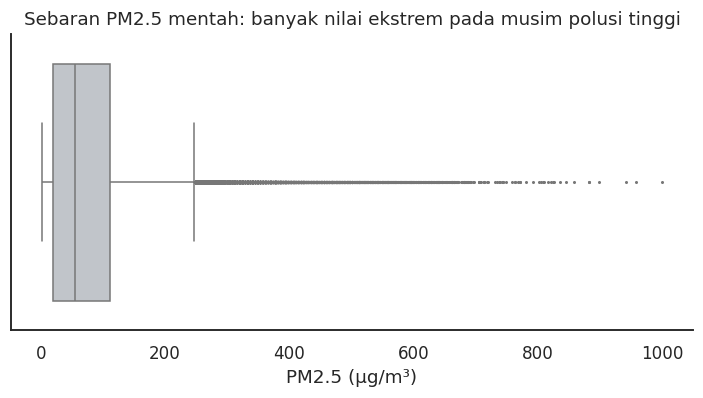

In [7]:
def hitung_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

outlier = pd.DataFrame({
    'jumlah_outlier': {c: hitung_outlier(df_raw[c].dropna()) for c in ['PM2.5','PM10','SO2','NO2','CO','O3']},
})
outlier['persen'] = (outlier['jumlah_outlier'] / len(df_raw) * 100).round(2)
display(outlier)

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.boxplot(x=df_raw['PM2.5'], color=GREY, fliersize=1, ax=ax)
ax.set_title('Sebaran PM2.5 mentah: banyak nilai ekstrem pada musim polusi tinggi')
ax.set_xlabel('PM2.5 (µg/m³)')
plt.show()

**Steps to Take:**
- **Missing value:** semua kolom numerik (PM2.5 8.739, PM10 6.449, SO2 9.021, NO2 12.116, CO 20.701, O3 13.277 baris, dan kolom cuaca) serta kolom arah angin `wd` (1.822 baris) memiliki nilai kosong. Penanganan: data diurutkan per stasiun dan waktu, lalu **interpolasi linear** (maksimal celah 24 jam) per stasiun. Sisa nilai kosong yang celahnya lebih panjang diisi dengan **median per stasiun-bulan**. Kolom `wd` diisi dengan nilai terdekat sebelum/sesudahnya (*forward/backward fill*) per stasiun.
- **Data tidak akurat:** terdapat sekitar 21 ribu baris dengan PM2.5 > PM10. Penanganan: nilai PM10 pada baris tersebut disamakan dengan PM2.5 (batas bawah logis).
- **Outlier:** nilai ekstrem PM2.5/PM10 (hingga 999) mencerminkan episode *haze* yang benar-benar terjadi, bukan kesalahan input. Penanganan: **dipertahankan**, dan analisis memakai rata-rata harian agar pengaruh lonjakan sesaat lebih terkendali.
- **Duplikat:** tidak ditemukan baris duplikat, sehingga tidak perlu tindakan.
- Nilai negatif pada TEMP dan DEWP adalah valid (suhu musim dingin Beijing), sehingga dibiarkan.

**Insight:**
- Kolom CO memiliki missing value terbanyak (sekitar 4,9%), tetapi seluruh kolom masih di bawah 5%, sehingga imputasi aman dilakukan tanpa membuang data.
- Tidak ada nilai negatif pada polutan, dan seluruh stasiun memiliki rentang waktu yang sama (tidak ada stasiun yang timpang).

### Cleaning Data

#### Membentuk kolom waktu dan mengurutkan data

In [8]:
df = df_raw.copy()
df['date'] = pd.to_datetime(df[['year','month','day','hour']])
df = df.sort_values(['station','date']).reset_index(drop=True)
df['periode'] = np.where(df['month'] >= 3, df['year'], df['year'] - 1)  # periode Maret-Februari
df['periode'] = df['periode'].astype(str) + '/' + (df['periode'] + 1).astype(str)
df[['date','station','periode']].head()

,date,station,periode
0,2013-03-01 00:00:00,Aotizhongxin,2013/2014
1,2013-03-01 01:00:00,Aotizhongxin,2013/2014
2,2013-03-01 02:00:00,Aotizhongxin,2013/2014
3,2013-03-01 03:00:00,Aotizhongxin,2013/2014
4,2013-03-01 04:00:00,Aotizhongxin,2013/2014


#### Fixing missing value

In [9]:
# 1) Interpolasi linear per stasiun (maks. celah 24 jam)
for c in num_cols:
    df[c] = df.groupby('station')[c].transform(lambda s: s.interpolate(limit=24, limit_direction='both'))

# 2) Sisa celah panjang diisi median per stasiun-bulan
for c in num_cols:
    df[c] = df[c].fillna(df.groupby(['station','month'])[c].transform('median'))

# 3) Arah angin: isi dengan nilai terdekat per stasiun
df['wd'] = df.groupby('station')['wd'].transform(lambda s: s.ffill().bfill())

print('Sisa missing value:', df[num_cols + ['wd']].isna().sum().sum())

Sisa missing value: 0


#### Fixing inaccurate value (PM2.5 > PM10)

In [10]:
mask = df['PM2.5'] > df['PM10']
print(f'Baris diperbaiki: {mask.sum()}')
df.loc[mask, 'PM10'] = df.loc[mask, 'PM2.5']
print('Sisa baris PM2.5 > PM10:', (df['PM2.5'] > df['PM10']).sum())

Baris diperbaiki: 22774
Sisa baris PM2.5 > PM10: 0


#### Membuat data harian per stasiun

In [11]:
# Analisis memakai rata-rata harian agar sesuai standar kualitas udara (batas 24 jam)
daily = (df.groupby(['station', df['date'].dt.normalize()])
           .agg(PM25=('PM2.5','mean'), PM10=('PM10','mean'), SO2=('SO2','mean'),
                NO2=('NO2','mean'), CO=('CO','mean'), O3=('O3','mean'),
                TEMP=('TEMP','mean'), WSPM=('WSPM','mean'), RAIN=('RAIN','sum'),
                periode=('periode','first'))
           .reset_index()
           .rename(columns={'date':'tanggal'}))
daily['bulan'] = daily['tanggal'].dt.month
daily['bulan_tahun'] = daily['tanggal'].dt.to_period('M').dt.to_timestamp()
print(daily.shape)
daily.head()

(17532, 14)


,station,tanggal,PM25,PM10,SO2,NO2,CO,O3,TEMP,WSPM,RAIN,periode,bulan,bulan_tahun
0,Aotizhongxin,2013-03-01,7.125000,10.750000,11.708333,22.583333,429.166667,63.875000,1.391667,3.254167,0.0,2013/2014,3,2013-03-01
1,Aotizhongxin,2013-03-02,30.750000,42.083333,36.625000,66.666667,824.916667,29.750000,0.616667,1.479167,0.0,2013/2014,3,2013-03-01
2,Aotizhongxin,2013-03-03,76.916667,120.541667,61.291667,81.000000,1620.625000,19.125000,5.566667,1.658333,0.0,2013/2014,3,2013-03-01
3,Aotizhongxin,2013-03-04,22.708333,44.583333,22.854167,46.187500,606.250000,53.750000,9.962500,2.404167,0.0,2013/2014,3,2013-03-01
4,Aotizhongxin,2013-03-05,148.875000,183.791667,93.875000,132.833333,2357.958333,68.458333,6.291667,1.129167,0.0,2013/2014,3,2013-03-01


**Insight:**
- Setelah cleaning, tidak ada lagi missing value dan tidak ada baris dengan PM2.5 > PM10.
- Data harian per stasiun (12 stasiun x 1.461 hari = 17.532 baris) siap dipakai untuk EDA dan dashboard.

## Exploratory Data Analysis (EDA)

### Explore statistik deskriptif

In [12]:
daily[['PM25','PM10','SO2','NO2','CO','O3','TEMP','WSPM']].describe().round(2)

,PM25,PM10,SO2,NO2,CO,O3,TEMP,WSPM
count,17532.00,17532.00,17532.00,17532.00,17532.00,17532.00,17532.00,17532.00
mean,79.84,106.25,15.87,50.50,1231.99,57.04,13.53,1.73
std,69.38,75.43,18.53,28.15,984.11,39.12,10.83,0.78
min,3.00,4.83,0.47,2.00,100.00,0.29,-15.68,0.17
25%,30.21,49.95,3.83,30.44,620.83,25.60,3.01,1.20
50%,60.54,88.95,8.96,45.58,950.00,51.38,15.01,1.56
75%,107.54,139.30,20.29,64.96,1491.67,81.58,23.48,2.06
max,567.42,584.67,274.36,205.38,9402.08,526.42,32.37,7.24


### Explore PM2.5 berdasarkan bulan dan periode

In [13]:
rata_bulan = daily.groupby('bulan')['PM25'].mean().round(1)
print('Rata-rata PM2.5 per bulan (semua stasiun):')
print(rata_bulan.to_string())
print()
rata_periode = daily.groupby('periode')['PM25'].mean().round(1)
print('Rata-rata PM2.5 per periode (Maret-Februari):')
print(rata_periode.to_string())
print()
print('Perubahan terhadap periode 2013/2014 (%):')
print(((rata_periode / rata_periode.iloc[0] - 1) * 100).round(1).to_string())

Rata-rata PM2.5 per bulan (semua stasiun):
bulan
1      93.8
2      89.2
3      94.6
4      73.3
5      63.3
6      68.8
7      71.6
8      53.5
9      61.3
10     91.6
11     93.3
12    103.8

Rata-rata PM2.5 per periode (Maret-Februari):
periode
2013/2014    87.0
2014/2015    81.4
2015/2016    72.9
2016/2017    78.1

Perubahan terhadap periode 2013/2014 (%):
periode
2013/2014     0.0
2014/2015    -6.4
2015/2016   -16.2
2016/2017   -10.2


### Explore PM2.5 berdasarkan stasiun

In [14]:
BATAS = 75  # batas rata-rata 24 jam PM2.5 (Standar China GB 3095-2012 Grade II), µg/m³
stasiun = (daily.assign(lewat=daily['PM25'] > BATAS)
                .groupby('station')
                .agg(rata_PM25=('PM25','mean'), persen_hari_lewat=('lewat','mean'))
                .sort_values('rata_PM25', ascending=False))
stasiun['persen_hari_lewat'] *= 100
stasiun.round(1)

,rata_PM25,persen_hari_lewat
station,,
Dongsi,86.1,43.5
Nongzhanguan,85.1,42.8
Wanshouxigong,85.1,42.8
Gucheng,84.1,43.0
Wanliu,83.5,42.8
Guanyuan,82.9,42.2
Aotizhongxin,82.7,42.0
Tiantan,82.0,41.3
Shunyi,79.6,40.8


### Explore pola jam dan faktor cuaca

In [15]:
pola_jam = df.groupby('hour')['PM2.5'].mean().round(1)
print(pola_jam.to_string())

hour
0     87.7
1     86.8
2     84.8
3     82.2
4     79.5
5     76.5
6     74.3
7     73.4
8     74.4
9     76.1
10    77.1
11    77.1
12    76.6
13    76.1
14    75.5
15    74.6
16    74.4
17    75.5
18    78.0
19    82.5
20    86.6
21    88.8
22    89.0
23    88.6


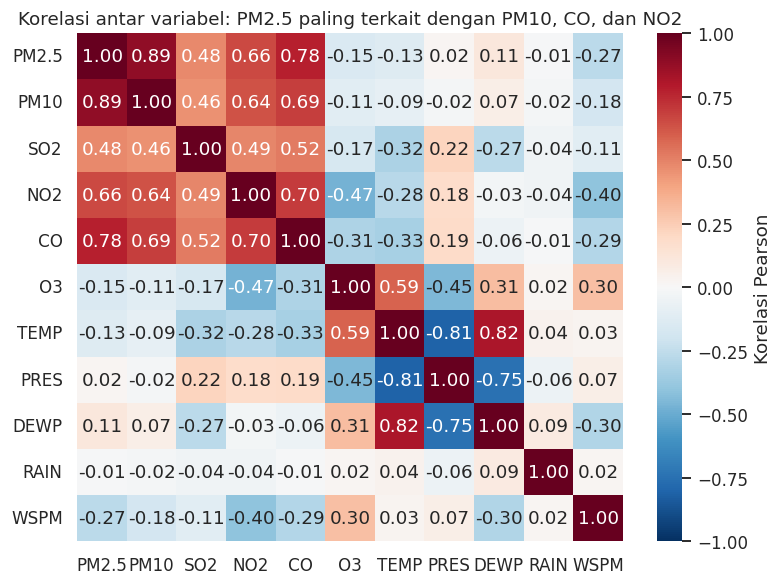

In [16]:
korelasi = df[['PM2.5','PM10','SO2','NO2','CO','O3','TEMP','PRES','DEWP','RAIN','WSPM']].corr().round(2)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            cbar_kws={'label': 'Korelasi Pearson'}, ax=ax)
ax.set_title('Korelasi antar variabel: PM2.5 paling terkait dengan PM10, CO, dan NO2')
plt.show()

**Insight:**
- Rata-rata PM2.5 tertinggi terjadi pada bulan Desember dan terendah pada bulan Agustus. Bulan Oktober sampai Maret konsisten tinggi.
- Rata-rata PM2.5 antar stasiun berkisar sekitar 67 hingga 86 µg/m³, dengan stasiun pusat kota cenderung lebih tinggi daripada stasiun pinggiran.
- PM2.5 berkorelasi kuat dengan PM10 (0,88), CO (0,79), dan NO2 (0,67), dan berkorelasi negatif dengan kecepatan angin (-0,27), artinya angin kencang membantu membersihkan polutan.
- Konsentrasi PM2.5 lebih tinggi pada malam hingga dini hari dan paling rendah sekitar pukul 07.00 sampai 08.00.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada bulan apa PM2.5 tertinggi dan terendah, dan apakah ada penurunan antar periode?

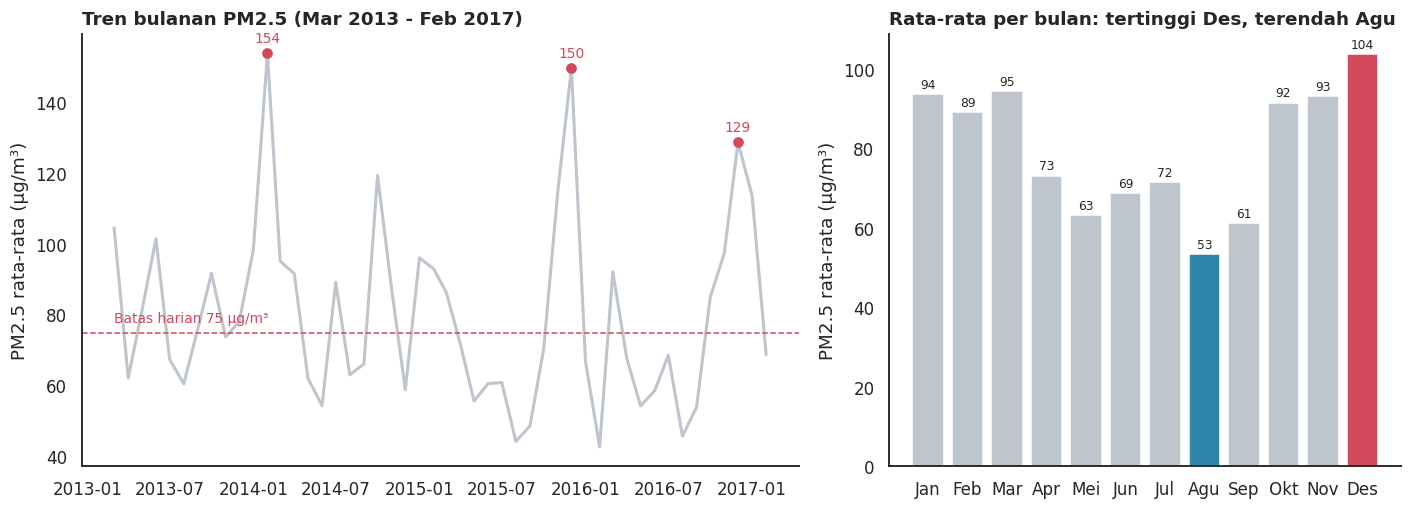

In [17]:
bulan_nama = ['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des']
bln = daily.groupby('bulan')['PM25'].mean()
tertinggi, terendah = bln.idxmax(), bln.idxmin()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1.4, 1]})

# (a) Tren bulanan seluruh periode
tren = daily.groupby('bulan_tahun')['PM25'].mean()
ax = axes[0]
ax.plot(tren.index, tren.values, color=GREY, lw=2)
ax.axhline(75, color=RED, ls='--', lw=1)
ax.text(tren.index[0], 78, 'Batas harian 75 µg/m³', color=RED, fontsize=9)
puncak = tren.nlargest(3)
ax.scatter(puncak.index, puncak.values, color=RED, zorder=3)
for t, v in puncak.items():
    ax.annotate(f'{v:.0f}', (t, v), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=9, color=RED)
ax.set_title('Tren bulanan PM2.5 (Mar 2013 - Feb 2017)', loc='left', fontweight='bold')
ax.set_ylabel('PM2.5 rata-rata (µg/m³)')

# (b) Rata-rata per bulan kalender
ax = axes[1]
warna = [RED if m == tertinggi else BLUE if m == terendah else GREY for m in bln.index]
bars = ax.bar([bulan_nama[m-1] for m in bln.index], bln.values, color=warna)
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5, f'{b.get_height():.0f}', ha='center', fontsize=8)
ax.set_title(f'Rata-rata per bulan: tertinggi {bulan_nama[tertinggi-1]}, terendah {bulan_nama[terendah-1]}', loc='left', fontweight='bold')
ax.set_ylabel('PM2.5 rata-rata (µg/m³)')
plt.tight_layout()
plt.show()

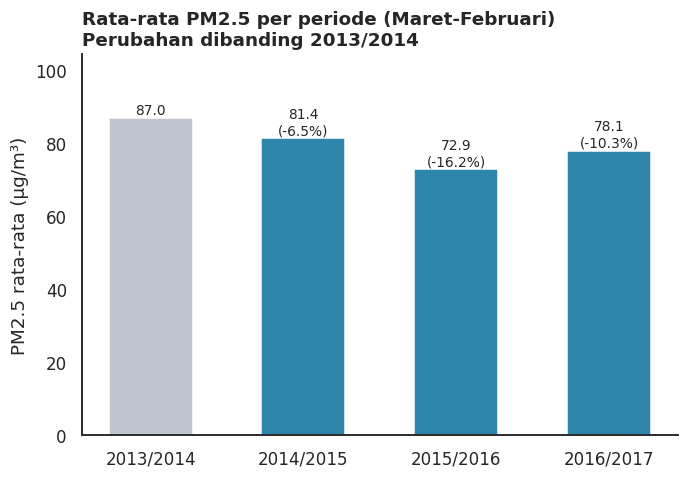

In [18]:
per = daily.groupby('periode')['PM25'].mean()
perubahan = (per / per.iloc[0] - 1) * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
warna = [GREY] + [BLUE if v < 0 else RED for v in perubahan.iloc[1:]]
bars = ax.bar(per.index, per.values, color=warna, width=0.55)
for b, p in zip(bars, perubahan):
    label = f'{b.get_height():.1f}' + ('' if p == 0 else f'\n({p:+.1f}%)')
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1, label, ha='center', fontsize=9)
ax.set_ylim(0, per.max() * 1.2)
ax.set_title('Rata-rata PM2.5 per periode (Maret-Februari)\nPerubahan dibanding 2013/2014', loc='left', fontweight='bold')
ax.set_ylabel('PM2.5 rata-rata (µg/m³)')
plt.show()

### Pertanyaan 2: Stasiun mana yang paling tinggi/rendah PM2.5 dan berapa persen hari melampaui 75 µg/m³?

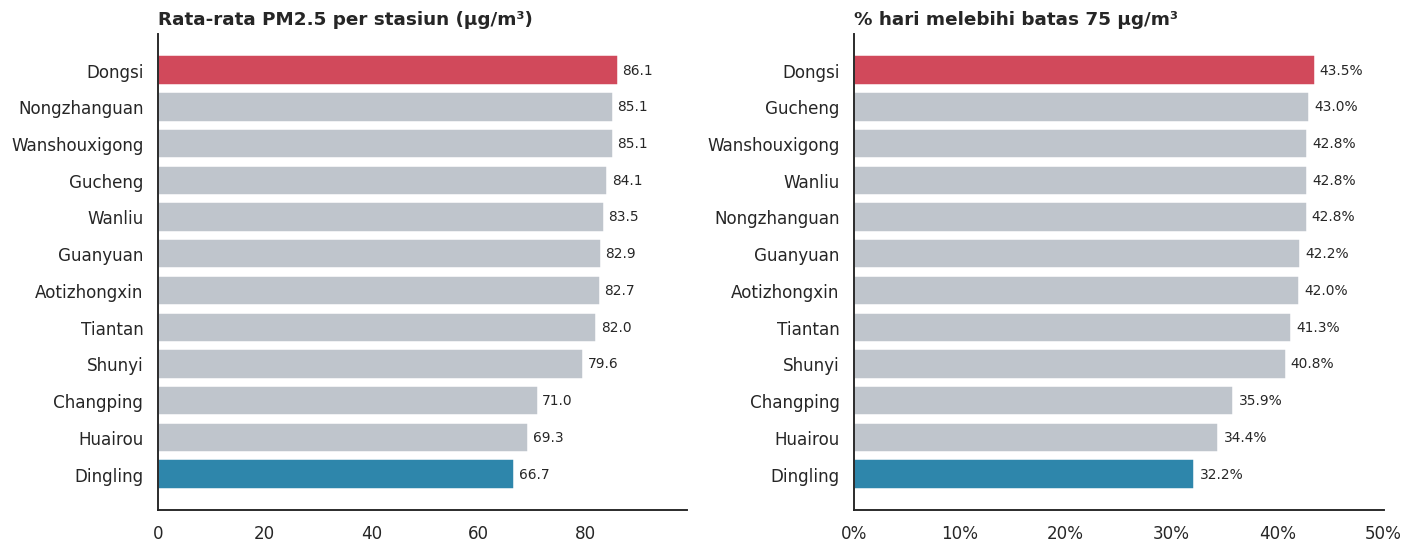

In [19]:
st = stasiun.sort_values('rata_PM25')
warna_a = [RED if s == st.index[-1] else BLUE if s == st.index[0] else GREY for s in st.index]
st2 = stasiun.sort_values('persen_hari_lewat')
warna_b = [RED if s == st2.index[-1] else BLUE if s == st2.index[0] else GREY for s in st2.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
axes[0].barh(st.index, st['rata_PM25'], color=warna_a)
for i, v in enumerate(st['rata_PM25']):
    axes[0].text(v + 0.8, i, f'{v:.1f}', va='center', fontsize=9)
axes[0].set_title('Rata-rata PM2.5 per stasiun (µg/m³)', loc='left', fontweight='bold')
axes[0].set_xlim(0, st['rata_PM25'].max() * 1.15)

axes[1].barh(st2.index, st2['persen_hari_lewat'], color=warna_b)
for i, v in enumerate(st2['persen_hari_lewat']):
    axes[1].text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=9)
axes[1].set_title('% hari melebihi batas 75 µg/m³', loc='left', fontweight='bold')
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_xlim(0, st2['persen_hari_lewat'].max() * 1.15)
plt.tight_layout()
plt.show()

**Insight:**
- **Pertanyaan 1:** PM2.5 tertinggi pada **Desember (~104 µg/m³)** dan terendah pada **Agustus (~54 µg/m³)**; hampir dua kali lipat. Rata-rata periodik turun dari 87,0 (2013/2014) menjadi 72,9 (2015/2016) lalu naik lagi menjadi 78,1 (2016/2017), sehingga penurunan belum konsisten.
- **Pertanyaan 2:** **Dongsi** (pusat kota) memiliki rata-rata PM2.5 tertinggi (~86 µg/m³) dengan ~43% hari melebihi 75 µg/m³, sedangkan **Dingling** terendah (~67 µg/m³, ~32% hari). Stasiun pinggiran utara/barat laut relatif lebih bersih daripada stasiun kota.

## Analisis Lanjutan (Opsional)

### Manual Grouping: kategori kualitas udara harian
**Tujuan:** mengelompokkan setiap hari ke dalam kategori kualitas udara berdasarkan rentang (binning) PM2.5 harian mengacu pada breakpoint Indeks Kualitas Udara China (HJ 633-2012), tanpa algoritma machine learning. Dengan ini, kita bisa melihat bukan hanya rata-rata, tetapi juga **seberapa sering** tiap stasiun mengalami hari berbahaya.

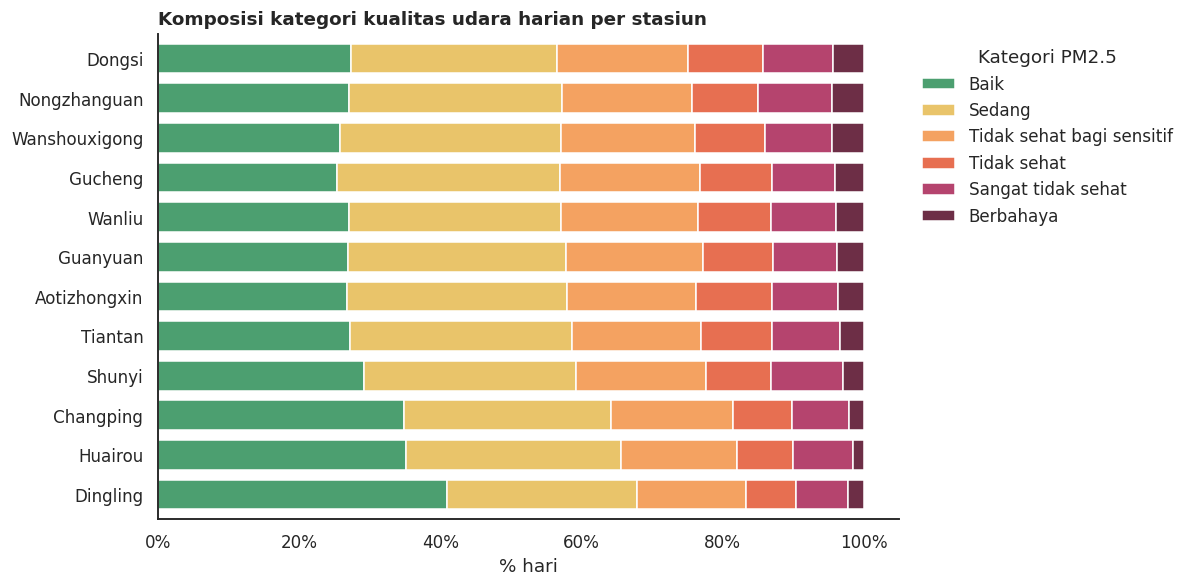

Persentase hari berkategori Tidak sehat atau lebih buruk (>115 µg/m³):
station
Dongsi           24.9
Nongzhanguan     24.3
Wanshouxigong    23.9
Aotizhongxin     23.8
Wanliu           23.5
Gucheng          23.3
Tiantan          23.1
Guanyuan         22.8
Shunyi           22.3
Changping        18.5
Huairou          17.9
Dingling         16.6


In [20]:
batas_bin = [0, 35, 75, 115, 150, 250, np.inf]
label_bin = ['Baik', 'Sedang', 'Tidak sehat bagi sensitif', 'Tidak sehat', 'Sangat tidak sehat', 'Berbahaya']
daily['kategori'] = pd.cut(daily['PM25'], bins=batas_bin, labels=label_bin, include_lowest=True)

kat = (daily.groupby(['station','kategori'], observed=False).size()
            .unstack(fill_value=0))
kat_persen = kat.div(kat.sum(axis=1), axis=0) * 100
kat_persen = kat_persen.loc[stasiun.index[::-1]]   # urut dari PM2.5 terendah ke tertinggi

warna_kat = ['#4C9F70', '#E9C46A', '#F4A261', '#E76F51', '#B5446E', '#6D2E46']
ax = kat_persen.plot(kind='barh', stacked=True, color=warna_kat, figsize=(11, 5.5), width=0.75)
ax.set_title('Komposisi kategori kualitas udara harian per stasiun', loc='left', fontweight='bold')
ax.set_xlabel('% hari')
ax.set_ylabel('')
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(title='Kategori PM2.5', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
plt.tight_layout()
plt.show()

print('Persentase hari berkategori Tidak sehat atau lebih buruk (>115 µg/m³):')
buruk = kat_persen[['Tidak sehat','Sangat tidak sehat','Berbahaya']].sum(axis=1).sort_values(ascending=False)
print(buruk.round(1).to_string())

### Geospatial Analysis: peta rata-rata PM2.5 per stasiun
**Tujuan:** melihat pola spasial polusi, yaitu apakah wilayah tertentu (pusat kota vs pinggiran) lebih tercemar. Peta dibuat dengan `folium`; ukuran dan warna lingkaran menunjukkan rata-rata PM2.5 stasiun.

> **Catatan:** dataset tidak menyertakan koordinat. Koordinat di bawah adalah **perkiraan** lokasi stasiun pemantau di Beijing dan dipakai untuk keperluan visualisasi.

In [24]:
peta = folium.Map(location=[40.0, 116.4], zoom_start=10, tiles=None, max_zoom=12)

folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles © Esri',
    name='Esri World Street Map',
    max_native_zoom=12,
    max_zoom=12
).add_to(peta)

for nama, r in geo.iterrows():
    folium.CircleMarker(
        location=[r['lat'], r['lon']], radius=r['rata_PM25'] / 4,
        color=warna_pm(r['rata_PM25']), fill=True, fill_opacity=0.7,
        tooltip=f"{nama}: {r['rata_PM25']:.1f} µg/m³ | {r['persen_hari_lewat']:.1f}% hari > 75"
    ).add_to(peta)
peta

**Insight:**
- Stasiun pusat kota (Dongsi, Nongzhanguan, Wanshouxigong, Gucheng) memiliki proporsi hari "tidak sehat" yang lebih besar dibandingkan stasiun pinggiran utara (Dingling, Huairou, Changping).
- Peta menunjukkan pola spasial: konsentrasi PM2.5 tertinggi berada di area padat perkotaan, sedangkan area utara yang lebih dekat dengan pegunungan relatif lebih bersih.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** PM2.5 bersifat sangat musiman. Puncaknya terjadi pada **Desember (~104 µg/m³)** dan terendah pada **Agustus (~54 µg/m³)**, dengan bulan Oktober sampai Maret konsisten tinggi. Rata-rata per periode turun 16,2% dari 2013/2014 ke 2015/2016, tetapi naik lagi ~7% pada 2016/2017, sehingga perbaikannya belum stabil.
- **Conclusion pertanyaan 2:** **Dongsi** adalah stasiun dengan polusi tertinggi (~86 µg/m³, ~43% hari melebihi 75 µg/m³), sedangkan **Dingling** terendah (~67 µg/m³, ~32%). Wilayah pusat kota konsisten lebih tercemar daripada pinggiran.

**Rekomendasi Action Item:**
- Terapkan **siaga polusi musiman** setiap Oktober sampai Maret (puncak Desember): pembatasan kendaraan/emisi industri, serta peringatan dini kepada kelompok sensitif.
- **Prioritaskan intervensi di wilayah pusat kota** (Dongsi, Nongzhanguan, Wanshouxigong, Gucheng), misalnya zona rendah emisi, pengendalian lalu lintas, dan penambahan sensor.
- Fokus pada pengendalian sumber **CO dan NO2** (emisi kendaraan/pembakaran) karena paling berkorelasi dengan PM2.5.
- Pantau pencapaian **target penurunan per periode** secara rutin, karena tren sempat naik kembali pada 2016/2017.

## Menyimpan Data untuk Dashboard

In [25]:
os.makedirs('dashboard', exist_ok=True)
main = daily.copy()
main['kategori'] = main['kategori'].astype(str)
main['lat'] = main['station'].map(lambda s: koordinat[s][0])
main['lon'] = main['station'].map(lambda s: koordinat[s][1])
main.to_csv('dashboard/main_data.csv', index=False)
print(main.shape)
main.head()

(17532, 17)


,station,tanggal,PM25,PM10,SO2,NO2,CO,O3,TEMP,WSPM,RAIN,periode,bulan,bulan_tahun,kategori,lat,lon
0,Aotizhongxin,2013-03-01,7.125000,10.750000,11.708333,22.583333,429.166667,63.875000,1.391667,3.254167,0.0,2013/2014,3,2013-03-01,Baik,39.982,116.397
1,Aotizhongxin,2013-03-02,30.750000,42.083333,36.625000,66.666667,824.916667,29.750000,0.616667,1.479167,0.0,2013/2014,3,2013-03-01,Baik,39.982,116.397
2,Aotizhongxin,2013-03-03,76.916667,120.541667,61.291667,81.000000,1620.625000,19.125000,5.566667,1.658333,0.0,2013/2014,3,2013-03-01,Tidak sehat bagi sensitif,39.982,116.397
3,Aotizhongxin,2013-03-04,22.708333,44.583333,22.854167,46.187500,606.250000,53.750000,9.962500,2.404167,0.0,2013/2014,3,2013-03-01,Baik,39.982,116.397
4,Aotizhongxin,2013-03-05,148.875000,183.791667,93.875000,132.833333,2357.958333,68.458333,6.291667,1.129167,0.0,2013/2014,3,2013-03-01,Tidak sehat,39.982,116.397
